# SGD NEER on one-minute quotes

Original corrected strategy: **-1.542 net Sharpe** with immediate fills, **-2.456** with one-minute delay, in 2024–2025. The selected ensemble scores **-0.354 / -1.209**. The one-hour equilibrium rule reaches **0.488** under immediate fills, but is negative in 2025 and after modest extra slippage; no robust improvement is established.

This notebook reads saved results. [Full methods and report](sgd_neer_minute_report.md). The final period was inspected before this follow-up, so it is not an untouched holdout. All Sharpe ratios below are daily, annualised, after recorded spreads and before financing.

In [1]:
from pathlib import Path
import datetime as dt
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

research = next(p/s for p in [Path.cwd(), *Path.cwd().parents]
                for s in ['', 'src/systematic_trading/research/sgd_neer_codex']
                if (p/s/'sgd_neer_results/minute/comparison_evaluation.csv').exists())
sys.path.insert(0, str(research.parents[1]))
from data.resampled_data_loader import get_resampled_quotes
from research.sgd_neer_codex.sgd_neer_backtest import prepare_basket

freq = pd.Timedelta(minutes=1)
instruments = ['USDSGD', 'EURUSD', 'AUDUSD', 'GBPUSD', 'USDJPY']
start_date, end_date = dt.date(2016,1,1), dt.date(2025,12,31)
def load_minute_prices():
    return get_resampled_quotes(instruments, start_date, end_date, freq=freq)
# To load the complete data for further work (several minutes):
# prices = load_minute_prices()
# data = prepare_basket(prices, freq=freq)

results = research/'sgd_neer_results/minute'
evaluation = pd.read_csv(results/'comparison_evaluation.csv')
development = pd.read_csv(results/'comparison_development.csv')
controls = pd.read_csv(results/'comparison_15min_controls.csv')
stress = pd.read_csv(results/'stress_evaluation.csv')
freeze = json.loads((results/'frozen_selection.json').read_text())
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False, 'axes.spines.right':False, 'font.size':10})
print('Frequency:', freq, '| Frozen shortlist:', ', '.join(freeze['selected']))


Frequency: 0 days 00:01:00 | Frozen shortlist: band_240m_cost2, band_60m_cost1, equilibrium_60m


## Quote quality and physical horizons

Features use 1/4/16/48-hour past returns, with volatility windows and annualisation scaled to minute data. Gaps invalidate features, but returns on held positions across gaps are retained. The cache permits ten minutes of forward filling; original tick age is unavailable. Quote-change freshness below is only a proxy.

In [2]:
display(pd.read_csv(results/'data_quality.csv').round(4))
display(pd.read_csv(results/'feature_coverage.csv').round(4))
manifest = json.loads((results/'data_manifest.json').read_text())
print('Median basket round-trip spread:', round(manifest['audit']['median_round_trip_bps'], 3), 'bp')


Median basket round-trip spread: 1.459 bp


,year,union_rows,common_rows,common_fraction,USDSGD_missing,EURUSD_missing,AUDUSD_missing,GBPUSD_missing,USDJPY_missing
0,2016,371280,370270,0.9973,1009,950,949,950,950
1,2017,370799,368414,0.9936,2385,1371,1371,1371,1371
2,2018,371279,370333,0.9975,905,832,835,869,830
3,2019,371279,369420,0.9950,1045,1572,1735,1582,1090
4,2020,372719,370198,0.9932,2420,2033,2042,2077,2012
5,2021,371280,369595,0.9955,1652,1247,1254,1251,1243
6,2022,371280,370161,0.9970,755,50,206,158,150
7,2023,371280,287566,0.7745,42852,42298,42500,42904,42516
8,2024,372719,367998,0.9873,1702,1182,2076,1278,2162
9,2025,371279,370081,0.9968,1002,966,940,996,908


,timestamp,fresh_proxy,features_usable
0,2016,0.9887,0.5709
1,2017,0.9811,0.5934
2,2018,0.9702,0.5518
3,2019,0.9946,0.5668
4,2020,0.9907,0.4980
5,2021,0.9824,0.3889
6,2022,0.9903,0.3392
7,2023,0.9658,0.3548
8,2024,0.9919,0.4550
9,2025,0.9953,0.5137


## Mean reversion and the cost threshold

Variance ratios use only contiguous windows. The regression table predicts a 30-minute forward return from a two-hour past return, with different execution delays. Anchors are spaced 30 minutes apart; HAC standard errors allow overlapping horizons.

,period,delay_minutes,beta,hac_t,r_squared,n
36,development,0,-0.04207,-12.34724,0.00586,71562
37,validation,0,-0.06318,-8.01923,0.01194,8299
38,evaluation,0,-0.04557,-5.42358,0.00696,23792
39,development,1,-0.03427,-10.68671,0.00384,71561
40,validation,1,-0.05178,-6.94491,0.00793,8299
41,evaluation,1,-0.04231,-5.08361,0.00557,23792
42,development,15,-0.01900,-5.81637,0.00125,71486
43,validation,15,-0.03281,-4.69839,0.00344,8176
44,evaluation,15,-0.02554,-4.36561,0.00217,23765


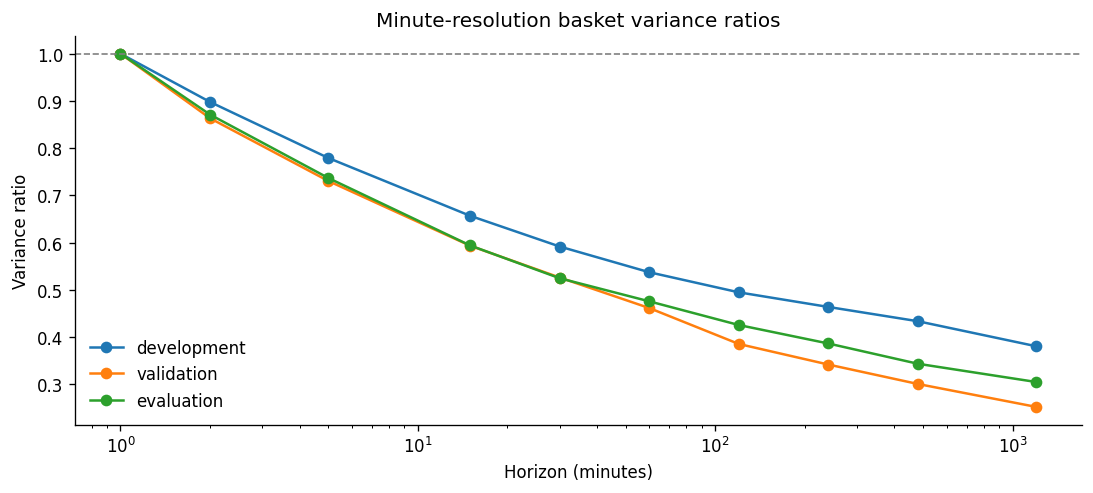

In [3]:
vr = pd.read_csv(results/'variance_ratio.csv')
reg = pd.read_csv(results/'return_regression.csv')
display(reg.query('past_minutes == 120 and future_minutes == 30')[['period','delay_minutes','beta','hac_t','r_squared','n']].round(5))
fig, ax = plt.subplots(figsize=(9,4), layout='constrained')
for period, part in vr.groupby('period', sort=False):
    ax.plot(part.minutes, part.variance_ratio, 'o-', label=period)
ax.set(xscale='log', xlabel='Horizon (minutes)', ylabel='Variance ratio', title='Minute-resolution basket variance ratios')
ax.axhline(1, color='0.5', ls='--', lw=1)
ax.legend(frameon=False)
fig.savefig(results/'minute_variance_ratio.png', dpi=160)
plt.show()


## All declared trials

2016 warms up the models. Selection ranks the minimum net Sharpe across 2017–2022, 2021–2022 and 2023, requiring 40 validation trade days. No selection uses the displayed 2024–2025 results.

In [4]:
board = pd.read_csv(results/'leaderboard.csv', index_col=0)
display(board.round(3))
print('Eligible and positive in all selection periods:', freeze['positive_in_all_selection_periods'])


Eligible and positive in all selection periods: []


,development,recent_development,validation,score,validation_trade_days
policy,,,,,
band_60m_cost2,0.180,0.343,1.605,0.180,20
equilibrium_240m,0.372,0.170,1.099,0.170,21
band_30m_cost1,0.150,0.266,0.980,0.150,25
band_30m_cost2,0.281,0.093,1.366,0.093,2
band_240m_cost2,-0.093,0.583,1.299,-0.093,63
band_60m_cost1,-0.095,-0.097,1.402,-0.097,62
equilibrium_60m,-0.175,0.254,4.052,-0.175,85
band_720m_cost2,0.187,0.574,-0.179,-0.179,62
band_240m_cost1,-0.269,-0.116,1.245,-0.269,73


## Execution delay versus signal frequency

Immediate fills observe quote t and earn only subsequent returns. Delays count common valid quotes and can exceed the nominal minute count around data gaps. The matched controls compute and fit signals every 15 minutes using the same minute source, then fill on the minute quote grid.

fill_delay_minutes,0,1,2,15
policy,,,,
band_240m_cost2,-1.082,-1.635,-1.569,-2.290
band_60m_cost1,-0.972,-1.868,-2.091,-3.171
band_720m_cost2,-0.656,-1.207,-1.134,-2.056
equilibrium_240m,0.221,-0.234,-0.540,-1.022
equilibrium_60m,0.488,-0.172,-0.701,-2.805
frozen_ensemble,-0.354,-1.209,-1.601,-3.333
legacy_corrected,-1.542,-2.456,-2.567,-3.740


fill_delay_minutes,0,1,15
policy,,,
band_240m_cost2,-0.866,-1.253,-1.442
band_720m_cost2,-0.949,-1.488,-2.161
equilibrium_240m,-1.061,-1.288,-1.786
legacy_corrected,-0.670,-0.881,-2.274


period,development,validation,2024,2025,evaluation
policy,,,,,
band_240m_cost2,-0.093,1.299,-0.852,-1.577,-1.082
band_60m_cost1,-0.095,1.402,-0.741,-1.508,-0.972
band_720m_cost2,0.187,-0.179,-1.057,-0.302,-0.656
equilibrium_240m,0.372,1.099,0.866,-0.110,0.221
equilibrium_60m,-0.175,4.052,2.200,-0.652,0.488
frozen_ensemble,-0.151,3.533,0.358,-1.181,-0.354
legacy_corrected,-0.451,-6.451,-1.269,-1.804,-1.542


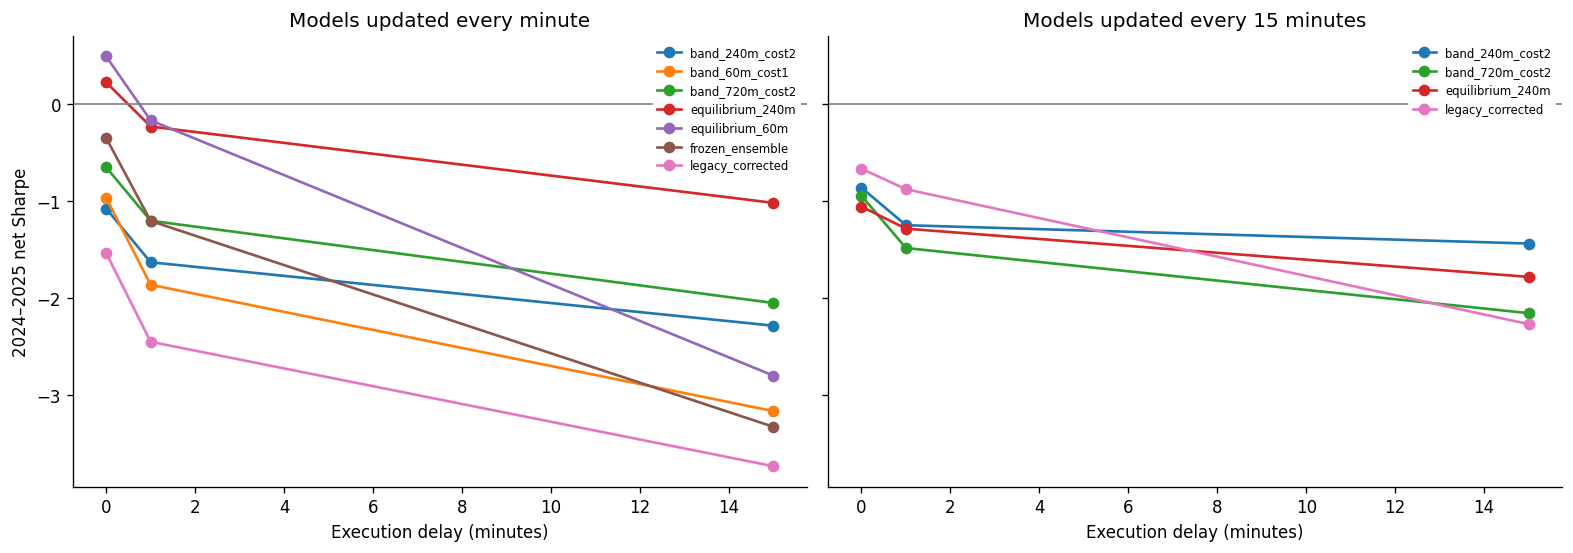

In [5]:
e = evaluation.query("period == 'evaluation'").pivot(index='policy', columns='fill_delay_minutes', values='sharpe')
c = controls.query("period == 'evaluation'").pivot(index='policy', columns='fill_delay_minutes', values='sharpe')
display(e.round(3))
display(c.round(3))
display(evaluation.query('fill_delay_minutes == 0').pivot(index='policy',columns='period',values='sharpe')[['development','validation','2024','2025','evaluation']].round(3))
fig, axes = plt.subplots(1,2,figsize=(13,4.5),layout='constrained',sharey=True)
colors = dict(zip(e.index, plt.rcParams['axes.prop_cycle'].by_key()['color']))
for ax, frame, title in [(axes[0], e[[0,1,15]], 'Models updated every minute'),
                         (axes[1], c[[0,1,15]], 'Models updated every 15 minutes')]:
    frame.T.plot(ax=ax, marker='o', linewidth=1.6, color=[colors[n] for n in frame.index])
    ax.axhline(0,color='0.5',lw=1)
    ax.set(xlabel='Execution delay (minutes)',ylabel='2024–2025 net Sharpe',title=title)
    ax.legend(loc='upper right',frameon=True,facecolor='white',edgecolor='none',framealpha=.95,fontsize=7)
fig.savefig(results/'minute_execution_comparison.png',dpi=160)
plt.show()


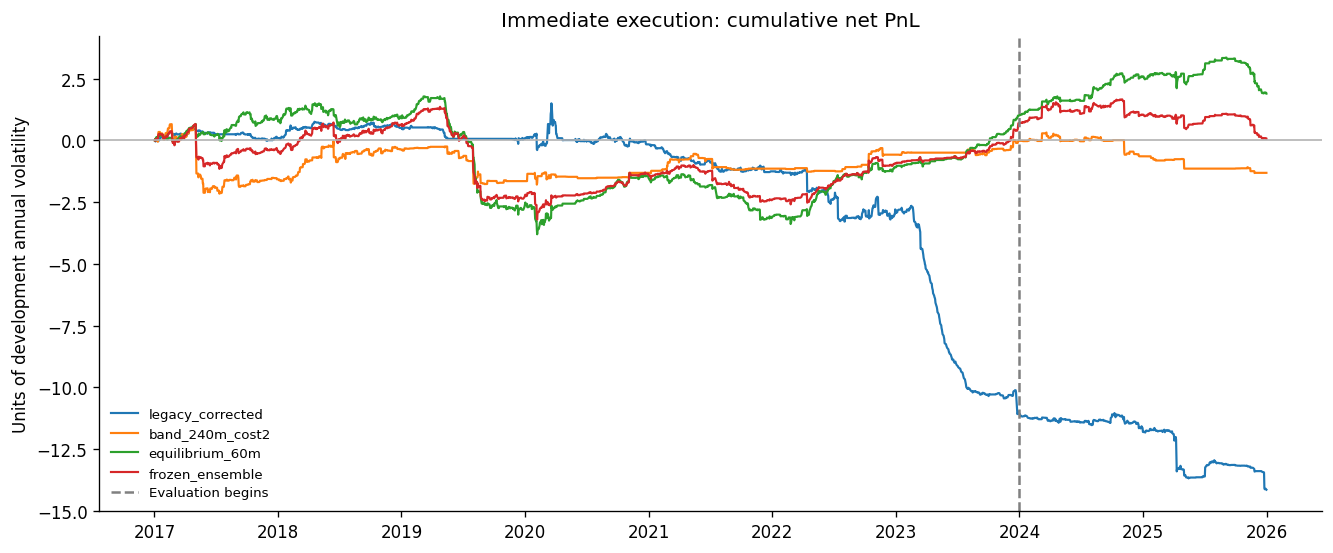

In [6]:
fig, ax = plt.subplots(figsize=(11,4.5), layout='constrained')
for name in ['legacy_corrected', freeze['selected'][0], 'equilibrium_60m', 'frozen_ensemble']:
    d = pd.read_csv(results/f'daily_{name}_fill0.csv.gz', index_col=0, parse_dates=True).net
    # Scale using development volatility only, to make target units comparable.
    scale = d.loc['2017':'2022'].std()*np.sqrt(252)
    ax.plot(d.loc['2017':].cumsum()/scale,label=name,lw=1.3)
ax.axvline(pd.Timestamp('2024-01-01'),ls='--',color='0.5',label='Evaluation begins')
ax.axhline(0,color='0.7',lw=1)
ax.set(title='Immediate execution: cumulative net PnL',ylabel='Units of development annual volatility')
ax.legend(frameon=False,fontsize=8)
fig.savefig(results/'minute_cumulative_pnl.png',dpi=160)
plt.show()


## Costs, quote changes and sampling uncertainty

The freshness proxy permits execution only when all five legs changed within two minutes of the fill timestamp; blocked trades leave the existing position live. Financing stress is illustrative, not actual swap data. Bootstrap intervals do not adjust for strategy selection or quote-quality bias.

In [7]:
display(stress.pivot(index=['policy','scenario'],columns='fill_delay_minutes',values='sharpe').round(3))
display(pd.read_csv(results/'bootstrap.csv').round(3))
display(pd.read_csv(results/'refitted_delay1.csv').query("period == 'evaluation'")[['policy','sharpe','gross_sharpe','trade_days']].round(3))


fill_delay_minutes                          0      1
policy           scenario                           
band_240m_cost2  1bp_per_roll_exposure -1.082 -1.635
                 base                  -1.082 -1.635
                 decisions_every_15min -1.555 -1.901
                 extra_0.25bp_per_leg  -1.551 -2.091
                 fresh_at_fill_2min    -1.085 -1.638
                 spread_x1.5           -1.480 -2.068
                 spread_x2             -1.838 -2.435
band_60m_cost1   1bp_per_roll_exposure -0.974 -1.870
                 base                  -0.972 -1.868
                 decisions_every_15min -2.400 -2.620
                 extra_0.25bp_per_leg  -2.231 -2.967
                 fresh_at_fill_2min    -0.980 -1.870
                 spread_x1.5           -1.993 -2.828
                 spread_x2             -2.815 -3.534
band_720m_cost2  1bp_per_roll_exposure -0.659 -1.210
                 base                  -0.656 -1.207
                 decisions_every_15min -1.335 -1.710
                 extra_0.25bp_per_leg  -1.449 -1.977
                 fresh_at_fill_2min    -0.679 -1.229
                 spread_x1.5           -1.353 -1.959
                 spread_x2             -1.986 -2.605
equilibrium_240m 1bp_per_roll_exposure  0.221 -0.234
                 base                   0.221 -0.234
                 decisions_every_15min -0.591 -0.930
                 extra_0.25bp_per_leg  -0.296 -0.784
                 fresh_at_fill_2min     0.221 -0.234
                 spread_x1.5           -0.307 -0.789
                 spread_x2             -0.829 -1.324
equilibrium_60m  1bp_per_roll_exposure  0.479 -0.183
                 base                   0.488 -0.172
                 decisions_every_15min -1.030 -1.332
                 extra_0.25bp_per_leg  -1.131 -1.820
                 fresh_at_fill_2min     0.488 -0.172
                 spread_x1.5           -1.066 -1.753
                 spread_x2             -2.575 -3.211
frozen_ensemble  1bp_per_roll_exposure -0.360 -1.217
                 base                  -0.354 -1.209
                 decisions_every_15min -1.917 -2.266
                 extra_0.25bp_per_leg  -1.866 -2.684
                 fresh_at_fill_2min    -0.357 -1.211
                 spread_x1.5           -1.714 -2.571
                 spread_x2             -2.910 -3.684
legacy_corrected 1bp_per_roll_exposure -1.881 -2.838
                 base                  -1.542 -2.456
                 decisions_every_15min -2.332 -2.508
                 extra_0.25bp_per_leg  -3.383 -4.466
                 fresh_at_fill_2min    -1.484 -2.484
                 spread_x1.5           -2.889 -3.810
                 spread_x2             -3.712 -4.565

,policy,fill_delay_minutes,low,median,high
0,legacy_corrected,0,-2.592,-1.582,0.119
1,legacy_corrected,1,-3.158,-2.505,-1.677
2,equilibrium_240m,0,-0.866,0.268,1.859
3,equilibrium_240m,1,-1.194,-0.190,1.170
4,band_720m_cost2,0,-1.995,-0.650,0.691
5,band_720m_cost2,1,-2.552,-1.232,0.177
6,band_240m_cost2,0,-2.011,-1.091,0.173
7,band_240m_cost2,1,-2.366,-1.678,-0.826
8,band_60m_cost1,0,-2.024,-0.968,0.289
9,band_60m_cost1,1,-2.615,-1.896,-1.058


,policy,sharpe,gross_sharpe,trade_days
3,band_240m_cost2,-1.529,-0.416,86
10,band_60m_cost1,-1.900,0.320,146
17,equilibrium_60m,-0.172,2.855,212


## Reproduction

```sh
poetry run python src/systematic_trading/research/sgd_neer_codex/run_sgd_neer_minute.py --stage all
poetry run pytest -q tests/test_sgd_neer_backtest.py
```

The stages resume using local cached inputs and signals; use a clean research cache/results directory after changing model code or input data. All saved protocols, fits, daily PnL and data manifests are in `sgd_neer_results/minute`. The original exploratory notebook is unchanged by this follow-up.